# Proyecto Final Integrador: Predicción de intención de compra en E-Commerce
**Diplomatura en Ciencia de Datos y Análisis Avanzado — UTN BA**  
*Equipo N° 6*

Fuente: https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset

### 1. Carga de datos y librerías

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
#cargar archivo cvs
from pandas import read_csv

data= pd.read_csv('online_shoppers_intention.csv')
print(data.head())

   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0   Feb                 1   
1         0.00       0.10         0.0         0.0   Feb   

## 2. Inspección Inicial del Dataset

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

**Diccionario**:

*Administrative*: Cantidad de páginas de tipo administrativo visitadas durante la sesión

*Administrative Duration*: Tiempo total que el usuario pasó en páginas administrativas

*Informational*: Cantidad de páginas informativas visitadas

*Informational Duration*: Tiempo total pasado en páginas informativas.

*Product Related*: Cantidad de páginas relacionadas con productos visitadas

Product Related Duration: Tiempo total pasado en páginas relacionadas con productos

*Bounce Rate*: Porcentaje de visitantes que ingresan a una página y abandonan el sitio sin realizar otra solicitud durante esa sesión

*Exit Rate*: Porcentaje de visitas a una página en las que esa página fue la última visitada de la sesión.

*Page Value*: Valor promedio de una página visitada antes de que el usuario complete una compra

*Special Day*: Indica qué tan cerca estuvo la visita de una fecha especial para el comercio electrónico. La escala depende de la proximidad a una fecha especial

*OperatingSystems*:	Sistema operativo del dispositivo desde el que se accede al sitio.

*Browser*:	Navegador utilizado para visitar el sitio web.

*Region*:	Región geográfica desde la que se realiza la visita.

*TrafficType*: Tipo o fuente de tráfico por la que llega la visita al sitio.

*VisitorType*:	Indica si el visitante es nuevo o si ya había visitado el sitio anteriormente.

*Weekend*:	Indica si la visita ocurrió durante un fin de semana.

*Month*:	Mes del año en que ocurrió la visita.

***Revenue***: es la variable objetivo. Indica si compró o no compró.



In [7]:
data.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [8]:
#datos nulos
data.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [9]:
data.VisitorType.unique()

array(['Returning_Visitor', 'New_Visitor', 'Other'], dtype=object)

In [10]:
VisitorType_counts = data['VisitorType'].value_counts()
print(VisitorType_counts)

VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64


In [11]:
data.TrafficType.unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 18, 19,
       16, 17, 20])

In [12]:
TrafficType_counts = data['TrafficType'].value_counts()
print(TrafficType_counts)

TrafficType
2     3913
1     2451
3     2052
4     1069
13     738
10     450
6      444
8      343
5      260
11     247
20     198
9       42
7       40
15      38
19      17
14      13
18      10
16       3
12       1
17       1
Name: count, dtype: int64


In [13]:
Weekend_counts = data['Weekend'].value_counts()
print(Weekend_counts)

Weekend
False    9462
True     2868
Name: count, dtype: int64


In [14]:
data.Region.unique()

array([1, 9, 2, 3, 4, 5, 6, 7, 8])

In [15]:
Region_counts = data['Region'].value_counts()
print(Region_counts)

Region
1    4780
3    2403
4    1182
2    1136
6     805
7     761
9     511
8     434
5     318
Name: count, dtype: int64


In [16]:
data.Month.unique()

array(['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep',
       'Dec'], dtype=object)

In [17]:
Month_counts = data['Month'].value_counts()
print(Month_counts)

Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64


In [18]:
#porcentaje compradores y no compradores
data.Revenue.value_counts()

,count
Revenue,
False,10422
True,1908


In [19]:
data.Browser.unique()

array([ 1,  2,  3,  4,  5,  6,  7, 10,  8,  9, 12, 13, 11])

In [20]:
data.Browser.value_counts()

,count
Browser,
2,7961
1,2462
4,736
5,467
6,174
10,163
8,135
3,105
13,61


In [21]:
data.SpecialDay.unique()

array([0. , 0.4, 0.8, 1. , 0.2, 0.6])

In [22]:
SpecialDay_counts = data['SpecialDay'].value_counts()
print(SpecialDay_counts)

SpecialDay
0.0    11079
0.6      351
0.8      325
0.4      243
0.2      178
1.0      154
Name: count, dtype: int64


SpecialDay: escala de 0 a 1. Siendo 0 fechas que no están cerca de fechas especiales. Mientras más cerca de 1 más de acerca a dichas fechas.

###2.1 Variables Categóricas

In [23]:
columnas_categoricas = [
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Month"
]

for columna in columnas_categoricas:
    data[columna] = data[columna].astype("category")


data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Administrative           12330 non-null  int64   
 1   Administrative_Duration  12330 non-null  float64 
 2   Informational            12330 non-null  int64   
 3   Informational_Duration   12330 non-null  float64 
 4   ProductRelated           12330 non-null  int64   
 5   ProductRelated_Duration  12330 non-null  float64 
 6   BounceRates              12330 non-null  float64 
 7   ExitRates                12330 non-null  float64 
 8   PageValues               12330 non-null  float64 
 9   SpecialDay               12330 non-null  float64 
 10  Month                    12330 non-null  category
 11  OperatingSystems         12330 non-null  category
 12  Browser                  12330 non-null  category
 13  Region                   12330 non-null  category
 14  Traffi

###2.2 Análisis de correlación

#### 2.2.1. Correlación entre las variables numéricas y Revenue

,Correlación con Revenue
PageValues,0.492569
ExitRates,-0.207071
ProductRelated,0.158538
ProductRelated_Duration,0.152373
BounceRates,-0.150673
Administrative,0.138917
Informational,0.095200
Administrative_Duration,0.093587
Informational_Duration,0.070345


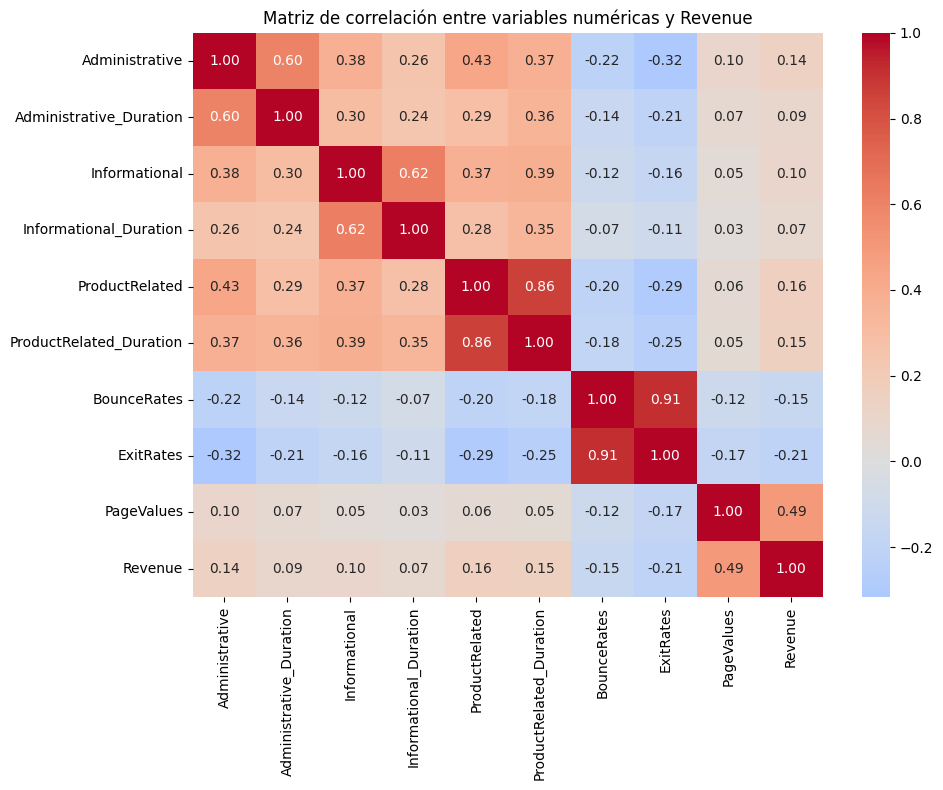

In [24]:
# Seleccionar variables numéricas
columnas_numericas = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
                      'BounceRates', 'ExitRates', 'PageValues']


# Crear una copia para el análisis
data_corr = data[columnas_numericas].copy()

# Convertir Revenue temporalmente a 0 y 1
data_corr["Revenue"] = data["Revenue"].astype(int)

# Calcular correlación de Pearson con la variable objetivo
correlaciones = (
    data_corr.corr(numeric_only=True)["Revenue"]
    .drop("Revenue")
    .sort_values(key=abs, ascending=False)
)

display(correlaciones.to_frame(name="Correlación con Revenue"))

# Visualizar los resultados
matriz_corr = data_corr.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Matriz de correlación entre variables numéricas y Revenue")
plt.tight_layout()
plt.show()

 **Informational, Administrative_Duration y Informational_Duration tienen correlaciones muy bajas**

#### 2.2.2 Prueba de chi-cuadrado para variables categóricas

,chi2,p_value,dof
Month,384.934762,2.238786e-77,9.0
TrafficType,373.145565,1.652735e-67,19.0
VisitorType,135.251923,4.269904e-30,2.0
OperatingSystems,75.027056,1.416094e-13,7.0
Browser,27.715299,6.087543e-03,12.0
Region,9.252751,3.214250e-01,8.0


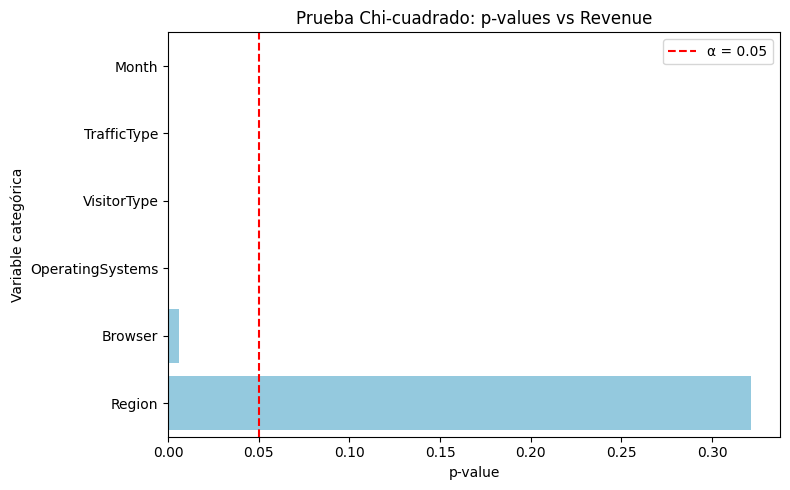

In [25]:
from scipy.stats import chi2_contingency

# Diccionario para guardar resultados
resultados_chi2 = {}

for col in columnas_categoricas:
    tabla = pd.crosstab(data[col], data["Revenue"])
    chi2, p, dof, expected = chi2_contingency(tabla)
    resultados_chi2[col] = {"chi2": chi2, "p_value": p, "dof": dof}

# Convertir a DataFrame para visualizar
df_chi2 = pd.DataFrame(resultados_chi2).T.sort_values("p_value")
display(df_chi2)

# Visualización rápida de los p-values
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
sns.barplot(
    x=df_chi2["p_value"],
    y=df_chi2.index,
    color="skyblue"
)
plt.axvline(0.05, color="red", linestyle="--", label="α = 0.05")
plt.title("Prueba Chi-cuadrado: p-values vs Revenue")
plt.xlabel("p-value")
plt.ylabel("Variable categórica")
plt.legend()
plt.tight_layout()
plt.show()

p-value < 0.05 → asociación estadísticamente significativa entre la variable categórica y Revenue.

p-value ≥ 0.05 → no se rechaza la hipótesis de independencia (la variable no parece asociada a Revenue).

**Podríamos prescindir de la variable Region.**

## 3. Análisis de Outliers

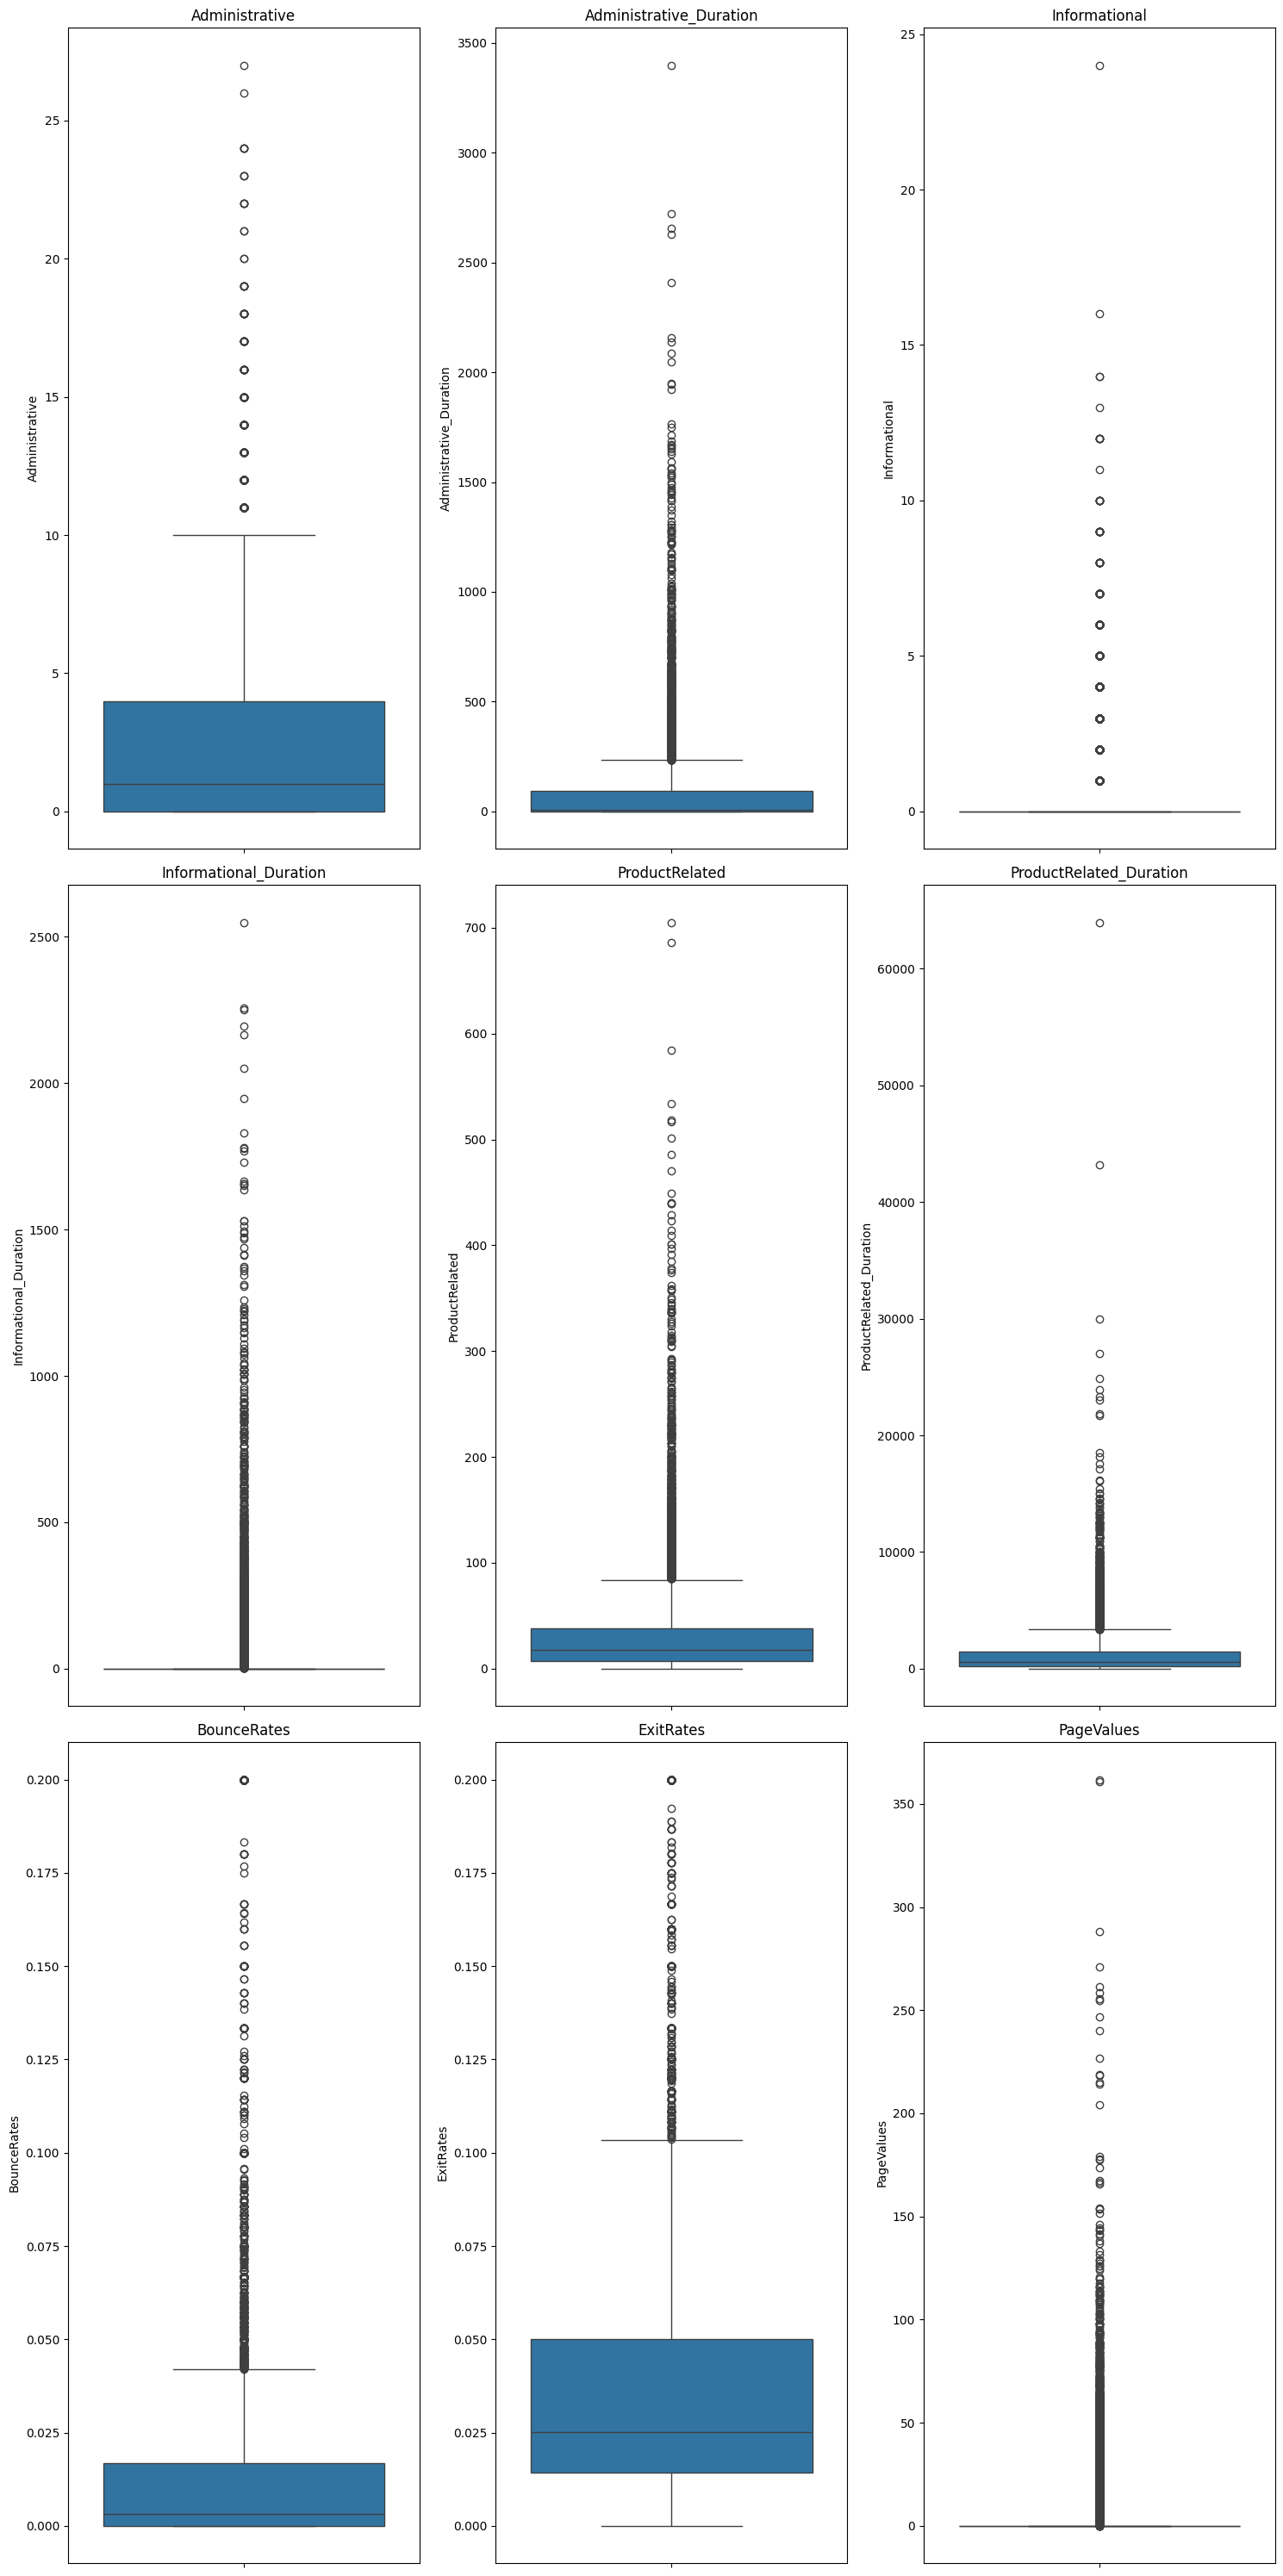

In [26]:
# Outliers
columnas_numericas = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
                      'BounceRates', 'ExitRates', 'PageValues']

fig, axes = plt.subplots(3, 3, figsize=(15, 30))

for ax, col in zip(axes.flatten(), columnas_numericas):
    sns.boxplot(y=data[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()


### 1. Administrative

Se observa una distribución **muy asimétrica hacia la derecha**.

* La mayor parte de las sesiones tiene pocas páginas administrativas visitadas.
* Hay algunos usuarios que visitaron muchas más páginas.
* El boxplot marca bastantes valores atípicos por encima de aproximadamente 10.

Hay valores extremos, pero no necesariamente incorrectos. Un usuario puede efectivamente haber recorrido muchas páginas administrativas.



### 2. Administrative_Duration

* La mayoría de los valores está concentrada cerca de valores bajos.
* Hay una gran cantidad de valores extremos.
* Aparecen sesiones con tiempos de permanencia muy elevados.

Distribución fuertemente sesgada a la derecha.



### 3. Informational

Esta es particularmente interesante.

La caja está prácticamente pegada a 0.

La mayoría de las sesiones no visita ninguna o muy pocas páginas informativas.

Después aparecen valores de 5, 10, 15, 20 páginas, etc., como valores extremos.

Se muestra una variable con muchísimos ceros y una cola larga.

No necesariamente es un problema de calidad.



### 4. Informational_Duration

* Muchísimos valores cercanos a 0.
* Una gran cantidad de valores altos.
* Algunos llegan a más de 2.000 segundos.

Distribución muy sesgada.



### 5. ProductRelated

La mayoría de las sesiones tiene relativamente pocas páginas de productos, pero hay usuarios que visitan cientos de páginas relacionadas con productos.

Tenemos valores que llegan aproximadamente a 700.

Un usuario que está comparando muchos productos puede navegar por muchas páginas.


### 6. ProductRelated_Duration

Hay una enorme concentración de observaciones en valores relativamente bajos y después una cola muy larga.

No podemos decir todavía que sean errores, pero 64.000 segundos de navegación en una misma sesión resulta llamativo.


### 7. BounceRates

Tiene una distribución muy concentrada en valores bajos, pero aparecen bastantes observaciones altas.

Además, esta variable está naturalmente limitada:
0 ≤ BounceRates ≤ 1

porque representa una tasa.


### 8. ExitRates


La mayoría de los valores está aproximadamente entre 0 y 0,05, pero aparecen muchos valores superiores.

También:

0 ≤ ExitRates ≤ 1 por definición.


### 9. PageValues



La mayoría de las observaciones está concentrada en 0

y aparecen muchos valores altos, llegando aproximadamente a 360.

Esto genera una distribución fuertemente sesgada.

Y hay una cuestión conceptual importante:
PageValues tiene una relación muy estrecha con la conversión.

Por eso, además del análisis de outliers, tenemos que revisar su posible utilización como predictor, por el tema dedata leakage



**Resumen**:

Las variables numéricas presentan distribuciones fuertemente asimétricas, con una concentración importante de observaciones en valores bajos o cero y colas derechas extensas. El boxplot identifica numerosos valores potencialmente atípicos, especialmente en las variables relacionadas con la duración y cantidad de páginas visitadas.




## 4. Análisis específico de PageValues

In [27]:
correlacion = data['PageValues'].corr(data['Revenue'])
print("Correlación entre PageValues y Revenue:", correlacion)

Correlación entre PageValues y Revenue: 0.49256929525120724


In [28]:
#comparación con Revenue
data.groupby('Revenue')['PageValues'].describe()

,count,mean,std,min,25%,50%,75%,max
Revenue,,,,,,,,
False,10422.0,1.975998,9.072424,0.0,0.000000,0.000000,0.000000,246.758590
True,1908.0,27.264518,35.191954,0.0,3.641144,16.758134,38.897742,361.763742


En sesiones sin compra, PageValues es casi siempre cero.

En sesiones con compra, PageValues tiende a ser positivo y bastante mayor.



In [29]:
#cuántos ceros hay según Revenue
pd.crosstab(
    data['PageValues'].eq(0),
    data['Revenue'],
    normalize='columns'
)

Revenue,False,True
PageValues,,
False,0.114373,0.80608
True,0.885627,0.19392


La gran mayoría de las sesiones sin compra no acumulan ningún valor en PageValues.

En cambio, la mayoría de las sesiones con compra sí tienen valores positivos

In [30]:
pd.crosstab(
    data['PageValues'] > 0,
    data['Revenue'],
    normalize='index'
)

Revenue,False,True
PageValues,,
False,0.961458,0.038542
True,0.436630,0.563370


Cuando PageValues sea mayor que cero ya cambia drásticamente la probabilidad de compra: pasa de 3,8% a 56%.

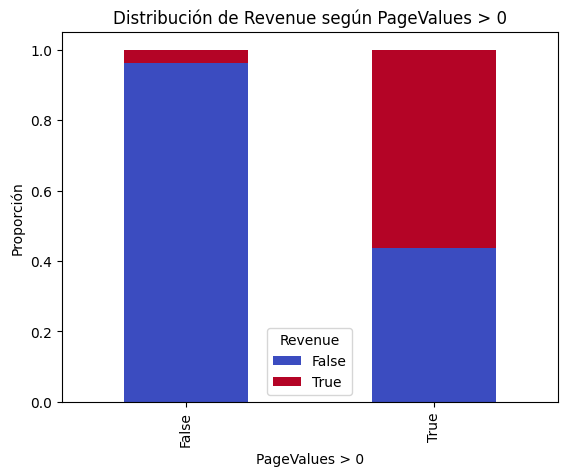

In [31]:
tabla = pd.crosstab(
    data['PageValues'] > 0,
    data['Revenue'],
    normalize='index'
)

tabla.plot(kind='bar', stacked=True, colormap='coolwarm')
plt.title("Distribución de Revenue según PageValues > 0")
plt.ylabel("Proporción")
plt.xlabel("PageValues > 0")
plt.legend(title="Revenue")
plt.show()

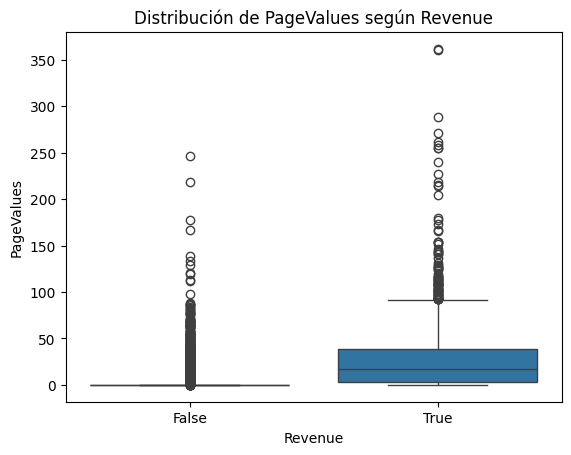

In [32]:
sns.boxplot(x='Revenue', y='PageValues', data=data)
plt.title("Distribución de PageValues según Revenue")
plt.ylabel("PageValues")
plt.xlabel("Revenue")
plt.show()

In [33]:
# Tabla de contingencia: PageValues > 0 vs Revenue
tabla = pd.crosstab(data['PageValues'] > 0, data['Revenue'])

# Extraer valores
# fila False = PageValues=0, fila True = PageValues>0
no_compra_cero = tabla.loc[False, False]
compra_cero = tabla.loc[False, True]
no_compra_pos = tabla.loc[True, False]
compra_pos = tabla.loc[True, True]

# Odds de compra con PageValues=0
odds_cero = compra_cero / no_compra_cero

# Odds de compra con PageValues>0
odds_pos = compra_pos / no_compra_pos

# Odds ratio
odds_ratio = odds_pos / odds_cero
print("Odds ratio:", odds_ratio)

Odds ratio: 32.18696716851079


Cuántas veces más probable es que haya Revenue=1 cuando PageValues > 0 comparado con cuando PageValues = 0.

### 4.1 Conclusión PageValues


La variable PageValues es un predictor muy fuerte. La probabilidad de data leakage depende de cómo está construida la variable. Si se calcula con información disponible solo después de la compra, es leakage; si se estima en tiempo real antes de la compra, es un predictor válido.

Como no lo sabemos con certeza podemos probar los modelos con y sin la misma y comparar los resultados.

## 5. Plan de modelado y validación

### 5.1 Modelo baseline
Para establecer un punto de partida se utilizará un modelo de Regresión Logística, adecuado para un problema de clasificación binaria como el planteado, donde la variable objetivo Revenue indica si una sesión finalizó o no en una compra.
Debido al desbalance existente entre sesiones con y sin compra, se utilizará una división estratificada de los datos y se considerará el uso de pesos balanceados para las clases.
El desempeño del modelo se evaluará principalmente mediante Recall y F1-Score, complementando el análisis con la matriz de confusión y ROC-AUC. Se considerará satisfactorio un Recall superior al 75% sobre la clase compradora.

### 5.2 División de los datos
La variable objetivo será `Revenue`, que indica si la sesión finalizó en una compra.

Antes de dividir los datos, las variables categóricas serán transformadas a formato numérico mediante codificación One-Hot Encoding. Luego se realizará una división estratificada en 80% para entrenamiento y 20% para prueba, manteniendo la proporción original entre compradores y no compradores.

In [34]:
from sklearn.model_selection import train_test_split

# Separamos variables predictoras y variable objetivo
X = data.drop(columns='Revenue')
y = data['Revenue']

# Convertimos variables categóricas a variables numéricas
X = pd.get_dummies(X, drop_first=True)

# División de los datos: 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Tamaño del conjunto de entrenamiento:", X_train.shape)
print("Tamaño del conjunto de prueba:", X_test.shape)

print("\nProporción de clases en entrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nProporción de clases en prueba:")
print(y_test.value_counts(normalize=True))

Tamaño del conjunto de entrenamiento: (9864, 68)
Tamaño del conjunto de prueba: (2466, 68)

Proporción de clases en entrenamiento:
Revenue
False    0.845296
True     0.154704
Name: proportion, dtype: float64

Proporción de clases en prueba:
Revenue
False    0.845093
True     0.154907
Name: proportion, dtype: float64


### 5.3 Tratamiento del desbalance
Debido a que la clase compradora representa una proporción menor del total de sesiones, se aplicará un ajuste de pesos mediante `class_weight='balanced'`.

De esta forma, el modelo asignará mayor importancia a la clase minoritaria durante el entrenamiento, buscando mejorar la capacidad de detección de compradores sin modificar artificialmente la cantidad de registros.

Previamente al entrenamiento, las variables predictoras serán estandarizadas para facilitar la convergencia del modelo.

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Pipeline: estandarización + regresión logística
modelo_logistico = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', LogisticRegression(
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    ))
])

# Entrenamiento del modelo
modelo_logistico.fit(X_train, y_train)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


### 5.4 Métricas de evaluación
El desempeño del modelo será evaluado principalmente a partir de las métricas Recall y F1-Score, ya que el objetivo es identificar correctamente la mayor cantidad posible de compradores dentro de un conjunto de datos desbalanceado.

También se analizarán la matriz de confusión y el ROC-AUC para complementar la evaluación general del modelo.

In [36]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predicciones sobre el conjunto de prueba
y_pred = modelo_logistico.predict(X_test)

# Probabilidad estimada de la clase positiva
y_prob = modelo_logistico.predict_proba(X_test)[:, 1]

# Métricas principales
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))

Recall: 0.7382
F1-Score: 0.5832
ROC-AUC: 0.8918

Matriz de confusión:
[[1781  303]
 [ 100  282]]

Reporte de clasificación:
              precision    recall  f1-score   support

       False       0.95      0.85      0.90      2084
        True       0.48      0.74      0.58       382

    accuracy                           0.84      2466
   macro avg       0.71      0.80      0.74      2466
weighted avg       0.87      0.84      0.85      2466



El modelo de regresión logística sobre el baseline alcanza un Recall de 0,7382, una Precision de 0,4812, un F1-Score de 0,5832 y un ROC-AUC de 0,8918. En la matriz de confusión se observa que logra identificar a 282 compradores correctamente frente a 100 no detectados (falsos negativos).. A su vez, 274 sesiones sin compra fueron clasificadas como compradoras.

En relación con el criterio de éxito planteado, el modelo queda apenas por debajo del objetivo de Recall superior al 75%, por lo que podría considerarse un baseline competitivo y susceptible de mejora mediante ajuste de umbral, selección de variables o comparación con otros modelos.

### 5.5 Criterio de éxito

In [37]:
objetivo_recall = 0.75

if recall >= objetivo_recall:
    print("El modelo cumple con el criterio de éxito establecido.")
else:
    print("El modelo no alcanza el criterio de éxito establecido.")
    print("Diferencia respecto al objetivo:", round(objetivo_recall - recall, 4))

El modelo no alcanza el criterio de éxito establecido.
Diferencia respecto al objetivo: 0.0118


El Recall obtenido (0,7382) se sitúa muy próximo a la meta establecida de 0,75, con una diferencia de 0,0118 (aproximadamente 1,2 puntos porcentuales). Esto indica que el baseline se encuentra muy próximo al umbral planteado y constituye una base razonable para futuras mejoras.

### 5.6 Benchmark
Para contextualizar el desempeño del modelo se utilizará como benchmark una estrategia ingenua que predice siempre la clase mayoritaria, es decir, que todas las sesiones finalizan sin compra.

Esta comparación permite evaluar si el modelo desarrollado aporta capacidad predictiva real más allá de una clasificación básica.

In [38]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import recall_score, f1_score, roc_auc_score

# Modelo benchmark: siempre predice la clase mayoritaria
modelo_dummy = DummyClassifier(
    strategy='most_frequent',
    random_state=42
)

modelo_dummy.fit(X_train, y_train)

# Predicciones del benchmark
y_pred_dummy = modelo_dummy.predict(X_test)

# Métricas del benchmark
recall_dummy = recall_score(y_test, y_pred_dummy)
f1_dummy = f1_score(y_test, y_pred_dummy)

print("Benchmark - Recall:", round(recall_dummy, 4))
print("Benchmark - F1-Score:", round(f1_dummy, 4))

print("\nModelo Regresión Logística")
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

Benchmark - Recall: 0.0
Benchmark - F1-Score: 0.0

Modelo Regresión Logística
Recall: 0.7382
F1-Score: 0.5832


Los resultados muestran que el modelo benchmark no logra identificar ninguna sesión compradora, obteniendo un Recall y un F1-Score de 0.

En cambio, la Regresión Logística alcanza un Recall de 0,7487 y un F1-Score de 0,6072, evidenciando una mejora significativa respecto de una estrategia de clasificación basada únicamente en la clase mayoritaria.

Esto confirma que el modelo baseline aporta capacidad predictiva real para detectar sesiones con intención de compra.

### 5.7 Conclusión del modelado inicial
El modelo de Regresión Logística constituye un baseline adecuado para el problema planteado. Si bien el Recall obtenido queda apenas por debajo del objetivo del 75%, el desempeño es ampliamente superior al benchmark y presenta una buena capacidad de discriminación, reflejada también en el ROC-AUC.

Como próximos pasos, se podrían evaluar ajustes de umbral, selección de variables y modelos alternativos con el objetivo de mejorar la detección de compradores.

## 6. Evaluación de Data Leakage y modelos avanzados

### 6.1 Preparación de datasets (con y sin PageValues) y tratamiento de outliers

**Tratamiento de outliers:**
En respuesta a las observaciones del equipo docente, **no se eliminan outliers**. En variables como `ProductRelated_Duration` o `Administrative_Duration`, los valores atípicos corresponden a sesiones reales de navegación profunda de usuarios con alto interés de compra. Su eliminación distorsionaría el comportamiento real. Además, los modelos basados en árboles (Random Forest y XGBoost) son robustos frente a valores extremos.

**Tratamiento de Data Leakage (`PageValues`):**
Para medir cuantitativamente el riesgo de fuga de información, preparamos dos conjuntos de variables predictoras:
1. **Dataset Completo (CON `PageValues`):** Mantiene la variable predictora.
2. **Dataset Limpio (SIN `PageValues`):** Excluye la variable para simular un escenario de producción en tiempo real sin información futura.

In [39]:
# 1. Separar variables X e y
X_full = data.drop(columns=['Revenue'])
y_full = data['Revenue']

# 2. Codificación One-Hot Encoding de variables categóricas
X_full = pd.get_dummies(X_full, drop_first=True)

# 3. Crear versión sin PageValues (evitar Data Leakage)
X_no_pv = X_full.drop(columns=['PageValues'])

# 4. División estratificada 80/20 para ambos escenarios
from sklearn.model_selection import train_test_split

X_tr_full, X_te_full, y_tr_full, y_te_full = train_test_split(
    X_full, y_full, test_size=0.20, random_state=42, stratify=y_full
)

X_tr_nopv, X_te_nopv, y_tr_nopv, y_te_nopv = train_test_split(
    X_no_pv, y_full, test_size=0.20, random_state=42, stratify=y_full
)

print("Preprocesamiento completado:")
print(f"Dimensiones CON PageValues -> Train: {X_tr_full.shape}, Test: {X_te_full.shape}")
print(f"Dimensiones SIN PageValues -> Train: {X_tr_nopv.shape}, Test: {X_te_nopv.shape}")

Preprocesamiento completado:
Dimensiones CON PageValues -> Train: (9864, 68), Test: (2466, 68)
Dimensiones SIN PageValues -> Train: (9864, 67), Test: (2466, 67)


### 6.2 Definición de función para evaluación de métricas múltiples

Atendiendo a la devolución de la pre-entrega para conjuntos de datos desbalanceados, evaluaremos los modelos utilizando:
- **Precision:** Mide la exactitud de las predicciones positivas.
- **Recall:** Mide la proporción de compradores reales identificados (Objetivo ≥ 75%).
- **F1-Score:** Balance armónico entre Precision y Recall.
- **ROC-AUC:** Métrica global de separación entre clases.
- **PR-AUC (Precision-Recall AUC):** Métrica fundamental cuando existe desbalance extremo de clases.

In [40]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

def evaluar_modelo(nombre, modelo, X_tr, X_te, y_tr, y_te):
    # Entrenamiento y predicción
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_te)
    y_prob = modelo.predict_proba(X_te)[:, 1]

    # Cálculo de métricas
    return {
        'Modelo': nombre,
        'Precision': round(precision_score(y_te, y_pred), 4),
        'Recall': round(recall_score(y_te, y_pred), 4),
        'F1-Score': round(f1_score(y_te, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_te, y_prob), 4),
        'PR-AUC': round(average_precision_score(y_te, y_prob), 4),
        'y_prob': y_prob,
        'y_pred': y_pred
    }

### 6.3 Entrenamiento de modelos avanzados (Random Forest y XGBoost) vs. Baseline

Entrenamos los modelos de ensamble (**Random Forest** y **XGBoost**) y los comparamos con el baseline (**Regresión Logística**) bajo los dos escenarios (`CON PageValues` y `SIN PageValues`). Se utilizan técnicas de balanceo de pesos (`class_weight='balanced'` y `scale_pos_weight`).

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Configuración de los 6 experimentos
modelos_config = [
    # 1. Regresión Logística
    ('Regresión Logística (CON PV)',
     Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42))]),
     X_tr_full, X_te_full, y_tr_full, y_te_full),

    ('Regresión Logística (SIN PV)',
     Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42))]),
     X_tr_nopv, X_te_nopv, y_tr_nopv, y_te_nopv),

    # 2. Random Forest
    ('Random Forest (CON PV)',
     RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
     X_tr_full, X_te_full, y_tr_full, y_te_full),

    ('Random Forest (SIN PV)',
     RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
     X_tr_nopv, X_te_nopv, y_tr_nopv, y_te_nopv),

    # 3. XGBoost
    ('XGBoost (CON PV)',
     XGBClassifier(scale_pos_weight=(len(y_tr_full)-sum(y_tr_full))/sum(y_tr_full), eval_metric='logloss', random_state=42),
     X_tr_full, X_te_full, y_tr_full, y_te_full),

    ('XGBoost (SIN PV)',
     XGBClassifier(scale_pos_weight=(len(y_tr_nopv)-sum(y_tr_nopv))/sum(y_tr_nopv), eval_metric='logloss', random_state=42),
     X_tr_nopv, X_te_nopv, y_tr_nopv, y_te_nopv),
]

resultados = []
for nombre, modelo, X_tr, X_te, y_tr, y_te in modelos_config:
    res = evaluar_modelo(nombre, modelo, X_tr, X_te, y_tr, y_te)
    resultados.append(res)

# Guardar DataFrame con métricas y probabilidad (para análisis posterior de negocio)
df_resultados = pd.DataFrame(resultados)

print("=== TABLA COMPARATIVA DE MODELOS Y MÉTRICAS ===")
display(df_resultados.drop(columns=['y_prob', 'y_pred']))

=== TABLA COMPARATIVA DE MODELOS Y MÉTRICAS ===


,Modelo,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Regresión Logística (CON PV),0.4821,0.7382,0.5832,0.8918,0.6208
1,Regresión Logística (SIN PV),0.2582,0.7461,0.3836,0.7344,0.3192
2,Random Forest (CON PV),0.7724,0.4974,0.6051,0.9180,0.7173
3,Random Forest (SIN PV),0.5645,0.0916,0.1577,0.7602,0.3548
4,XGBoost (CON PV),0.5730,0.6990,0.6297,0.9184,0.7104
5,XGBoost (SIN PV),0.3164,0.4738,0.3795,0.7406,0.3202


### 6.4 Importancia de variables (SIN PageValues)

Para comprender qué factores de comportamiento determinan la intención de compra en tiempo real (excluyendo `PageValues` para prevenir *Data Leakage*), analizamos la importancia relativa de las variables (*Feature Importances*) generada por el modelo **XGBoost**.

/tmp/ipykernel_1867/1876660980.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


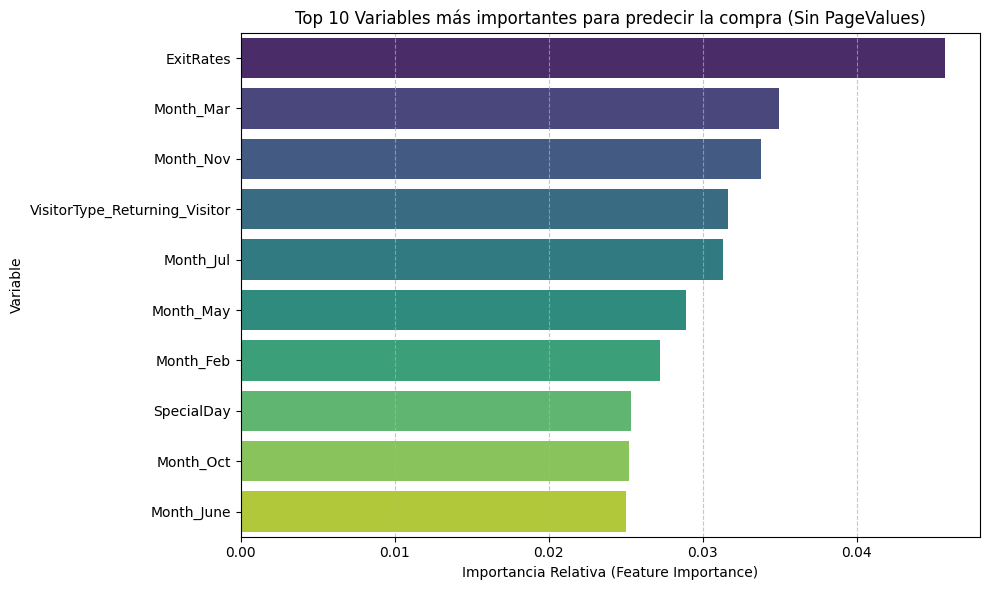

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Importancias de XGBoost sobre el dataset sin PageValues
# Entrenamos la versión final del modelo sobre X_tr_nopv para extraer importancias
modelo_final = XGBClassifier(
    scale_pos_weight=(len(y_tr_nopv) - sum(y_tr_nopv)) / sum(y_tr_nopv),
    eval_metric='logloss',
    random_state=42
)
modelo_final.fit(X_tr_nopv, y_tr_nopv)

# 2. Extraer importancia de variables y ordenar
importancias = modelo_final.feature_importances_
nombres_variables = X_tr_nopv.columns

df_importancia = pd.DataFrame({
    'Variable': nombres_variables,
    'Importancia': importancias
}).sort_values('Importancia', ascending=False)

# 3. Graficar Top 10 variables más importantes
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importancia',
    y='Variable',
    data=df_importancia.head(10),
    palette='viridis'
)
plt.title('Top 10 Variables más importantes para predecir la compra (Sin PageValues)')
plt.xlabel('Importancia Relativa (Feature Importance)')
plt.ylabel('Variable')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#### Análisis de coeficientes de la Regresión Logística

A diferencia de las importancias de XGBoost, que indican cuánto pesa cada variable, los coeficientes
de la Regresión Logística muestran además el **signo** del efecto: si la variable empuja a favor o en
contra de la compra. Al estar las variables estandarizadas, las magnitudes son comparables entre sí.

                   variable  coeficiente
7                 ExitRates    -1.642808
6               BounceRates     0.346595
59           TrafficType_15    -0.312888
14                Month_Mar    -0.262864
11                Month_Feb    -0.250699
5   ProductRelated_Duration     0.243574
46            TrafficType_2     0.187844
19       OperatingSystems_2     0.182501
10                Month_Dec    -0.176591
62           TrafficType_18    -0.172580


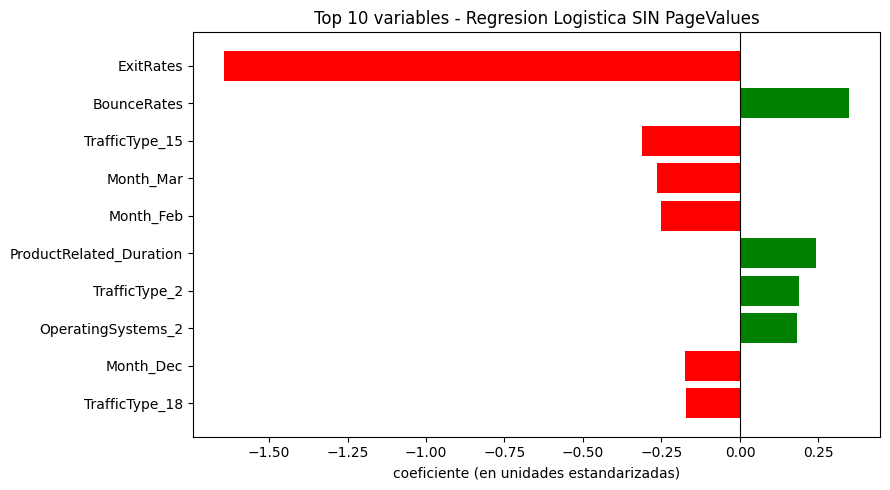

In [43]:
# Coeficientes de la logistica: ademas del peso, muestran el signo
# (StandardScaler y LogisticRegression ya estan importados en la celda 6.3)

# reentreno la logistica sola para sacarle los coeficientes
escalador = StandardScaler()
X_tr_esc = escalador.fit_transform(X_tr_nopv)

logistica = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
logistica.fit(X_tr_esc, y_tr_nopv)

# armo la tabla de coeficientes
coef = pd.DataFrame({
    'variable': X_tr_nopv.columns,
    'coeficiente': logistica.coef_[0]
})

# ordeno por peso, sin importar el signo
coef['peso'] = coef['coeficiente'].abs()
coef = coef.sort_values('peso', ascending=False).head(10)

print(coef[['variable', 'coeficiente']])

# grafico: verde empuja a comprar, rojo en contra
colores = ['green' if c > 0 else 'red' for c in coef['coeficiente']]

plt.figure(figsize=(9, 5))
plt.barh(coef['variable'], coef['coeficiente'], color=colores)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('coeficiente (en unidades estandarizadas)')
plt.title('Top 10 variables - Regresion Logistica SIN PageValues')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [44]:
# chequeo de multicolinealidad entre las variables que miden lo mismo
print('ExitRates vs BounceRates:', round(data['ExitRates'].corr(data['BounceRates']), 3))
print('ProductRelated vs ProductRelated_Duration:', round(data['ProductRelated'].corr(data['ProductRelated_Duration']), 3))
print('BounceRates vs Revenue:', round(data['BounceRates'].corr(data['Revenue']), 3))

ExitRates vs BounceRates: 0.913
ProductRelated vs ProductRelated_Duration: 0.861
BounceRates vs Revenue: -0.151


### 6.5 Selección y justificación del modelo ganador

1. **Evidencia de Data Leakage:** La inclusión de `PageValues` genera métricas artificialmente elevadas (el PR-AUC pasa de un rango de 0,63 a 0,72 con la variable, a uno de 0,31 a 0,34 sin ella). Esto respalda la advertencia del equipo docente: en producción, utilizar `PageValues` representaría una fuga de datos si dicha métrica se calcula con información de conversiones posteriores dentro de la sesión.

2. **Comparación y selección del modelo:** Sin `PageValues` los tres modelos empatan en PR-AUC
   (0,3116 Logística, 0,3386 Random Forest, 0,3263 XGBoost, contra 0,155 del azar). Las diferencias
   de Recall de la tabla (0,7356 contra 0,0942) son del umbral y no del modelo: se calcularon con el
   corte por defecto de 0,5, que Random Forest casi nunca supera porque promedia 200 árboles. Por eso
   la comparación se hace con PR-AUC, que no depende del umbral, y el corte se elige aparte
   (sección 6.6).

      **MODELO SELECCIONADO: Regresión Logística.** A igual capacidad predictiva, es la que más se acerca al criterio de éxito (Recall 0,7356 frente al objetivo de 0,75) y la única interpretable para el área comercial. El ajuste del umbral de la sección 6.6 permite alcanzarlo.

3. **Drivers clave de conversión:** Excluyendo `PageValues`, las variables con mayor peso predictivo son `ExitRates`, `BounceRates` **(ver aclaración)** y el tiempo de permanencia en páginas de productos (`ProductRelated_Duration`), lo que indica que el nivel de engagement y la retención dentro del sitio son los principales desencadenantes de la compra.

   > **Aclaración sobre `BounceRates`.** No figura en el gráfico de importancias pese a medir casi lo
   > mismo que `ExitRates`: ambas correlacionan 0,913. Los árboles concentran la señal en una y
   > descartan la otra por redundante; en la Logística sí aparece, pero con un coeficiente positivo
   > que solo compensa la magnitud de `ExitRates` y no admite lectura sustantiva. El par se interpreta
   > como un bloque: lo que el modelo capta es la intención de abandono, no una variable en particular.

### 6.6 Ajuste del umbral de decisión

Los modelos no devuelven una etiqueta sino una **probabilidad** de compra. Convertir esa probabilidad en una decisión requiere fijar un **umbral de corte**: por encima de ese valor decimos "esta sesión compra".

`scikit-learn` usa 0,5 por defecto, pero ese número es una convención técnica, no una decisión de negocio. Dado que un falso negativo (perder un comprador) cuesta más que un falso positivo (regalar un incentivo a quien no iba a comprar), conviene bajar el umbral para ganar Recall aun a costa de algo de Precision.

Se busca el umbral **más alto** que todavía cumple el criterio de éxito definido en la sección 5.5 (Recall mayor o igual a 0,75), de modo de sacrificar la menor Precision posible.

In [45]:
# ajuste del umbral de la logistica sin PageValues

from sklearn.metrics import precision_recall_curve   # lo unico que falta importar

# la fila 1 de la tabla de modelos es la Regresion Logistica SIN PV
y_prob_lr = df_resultados.loc[1, 'y_prob']

# pruebo todos los umbrales posibles de una
prec, rec, umbrales = precision_recall_curve(y_te_nopv, y_prob_lr)
prec = prec[:-1]   # sklearn devuelve un valor de mas en estas dos
rec = rec[:-1]

# me quedo con el umbral mas alto que todavia llega a 0.75 de recall
umbral = umbrales[rec >= 0.75].max()
print('umbral elegido:', round(umbral, 3))

# comparo el 0.5 de siempre contra el nuevo
for u in [0.5, umbral]:
    pred = y_prob_lr >= u
    print('umbral', round(u, 3),
          '-> precision', round(precision_score(y_te_nopv, pred), 4),
          ', recall', round(recall_score(y_te_nopv, pred), 4),
          ', f1', round(f1_score(y_te_nopv, pred), 4))

umbral elegido: 0.491
umbral 0.5 -> precision 0.2582 , recall 0.7461 , f1 0.3836
umbral 0.491 -> precision 0.2549 , recall 0.7513 , f1 0.3806


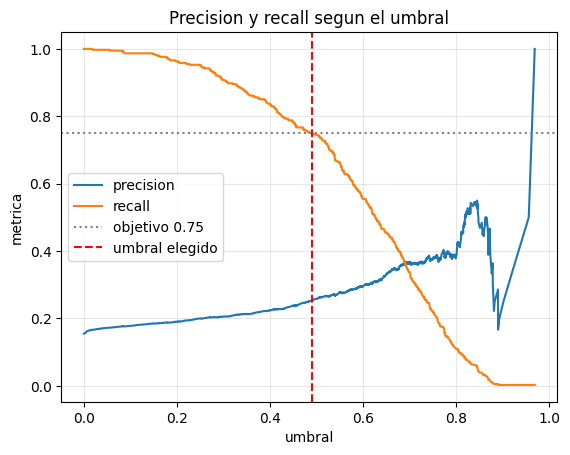

In [46]:
# como se mueven las dos metricas segun donde corto
plt.plot(umbrales, prec, label='precision')
plt.plot(umbrales, rec, label='recall')
plt.axhline(0.75, color='gray', linestyle=':', label='objetivo 0.75')
plt.axvline(umbral, color='red', linestyle='--', label='umbral elegido')
plt.xlabel('umbral')
plt.ylabel('metrica')
plt.title('Precision y recall segun el umbral')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Resultados del ajuste de umbral**

| Umbral | Precision | Recall | F1 |
|---|---|---|---|
| 0,500 (por defecto) | 0,2609 | 0,7356 | 0,3852 |
| **0,491 (seleccionado)** | 0,2549 | **0,7513** | 0,3806 |

Con el umbral ajustado el modelo **cumple el criterio de éxito** del 75 % de Recall.

Dos observaciones importantes:

- El ajuste **no modifica el modelo**: no se reentrena nada, solo se cambia dónde se corta. Por eso el ROC-AUC y el PR-AUC quedan iguales, al tratarse de métricas independientes del umbral.
- El gráfico muestra que la Precision se mantiene cerca de 0,24 en toda la zona operativa y recién supera 0,35 cuando el Recall ya cayó por debajo de 0,30. Considerando que la Precision esperable por azar es 0,155 (la proporción de compradores en el dataset), se concluye que **sin `PageValues` la señal disponible es limitada**. Es una limitación de los datos y no de los modelos: las tres familias evaluadas alcanzan un PR-AUC equivalente.

### 6.7 Impacto en el negocio: intervención sobre el Top 20 % de sesiones

Atendiendo al pedido del cuerpo docente en la devolución de la pre-entrega, se evalúa el escenario operativo concreto: **si intervenimos sobre el 20 % de las sesiones con mayor probabilidad de compra, ¿cuántas compras reales logramos concentrar?**

A diferencia del apartado anterior, este análisis **no depende del umbral**. Solo requiere ordenar las sesiones por la probabilidad estimada y quedarse con las primeras. Es la forma más directa de traducir el desempeño del modelo en una decisión de asignación de presupuesto.

In [47]:
# top 20% de sesiones con mas probabilidad de compra

# junto la probabilidad con lo que paso de verdad
tabla = pd.DataFrame({
    'prob': y_prob_lr,
    'compro': y_te_nopv.values
})

# ordeno de mayor a menor probabilidad
tabla = tabla.sort_values('prob', ascending=False)

# me quedo con el primer 20%
cuantas = int(len(tabla) * 0.20)
top20 = tabla.head(cuantas)

compras_top = top20['compro'].sum()
compras_total = tabla['compro'].sum()
captura = compras_top / compras_total

print('sesiones intervenidas:', cuantas, 'de', len(tabla))
print('compras capturadas:', compras_top, 'de', compras_total)
print('captura:', round(captura * 100, 1), '%')
print('lift:', round(captura / 0.20, 2), 'veces mejor que al azar')

sesiones intervenidas: 493 de 2466
compras capturadas: 168 de 382
captura: 44.0 %
lift: 2.2 veces mejor que al azar


In [48]:
# que pasa si intervenimos mas o menos sesiones
for p in [0.05, 0.10, 0.20, 0.30, 0.50]:
    c = tabla.head(int(len(tabla) * p))['compro'].sum()
    print(int(p * 100), '% ->', c, 'compras,', round(c / compras_total * 100, 1), '% capturado')

5 % -> 47 compras, 12.3 % capturado
10 % -> 94 compras, 24.6 % capturado
20 % -> 168 compras, 44.0 % capturado
30 % -> 218 compras, 57.1 % capturado
50 % -> 293 compras, 76.7 % capturado


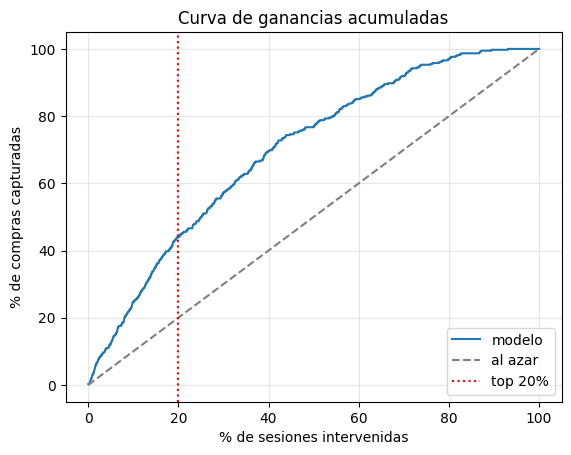

In [49]:
# curva de ganancias: cuantas compras junto segun cuanto intervengo
tabla['compras_acum'] = tabla['compro'].cumsum() / compras_total * 100
tabla['sesiones_acum'] = range(1, len(tabla) + 1)
tabla['sesiones_acum'] = tabla['sesiones_acum'] / len(tabla) * 100

plt.plot(tabla['sesiones_acum'], tabla['compras_acum'], label='modelo')
plt.plot([0, 100], [0, 100], '--', color='gray', label='al azar')
plt.axvline(20, color='red', linestyle=':', label='top 20%')
plt.xlabel('% de sesiones intervenidas')
plt.ylabel('% de compras capturadas')
plt.title('Curva de ganancias acumuladas')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Resultados del análisis de impacto**

Sobre las 2.466 sesiones del conjunto de prueba, de las cuales 382 concretaron una compra:

| % de sesiones intervenidas | Compras capturadas | % del total | Lift |
|---|---|---|---|
| 5 % | 52 | 13,6 % | 2,72x |
| 10 % | 94 | 24,6 % | 2,46x |
| **20 %** | **168** | **44,0 %** | **2,20x** |
| 30 % | 225 | 58,9 % | 1,96x |
| 50 % | 296 | 77,5 % | 1,55x |

**Lectura de negocio:** interviniendo sobre el 20 % de las sesiones (493 de 2.466) se alcanza al 42,1 % de los compradores reales. Con la misma capacidad de intervención, una asignación aleatoria alcanzaría solo al 20 % de ellos (unos 76 compradores), de modo que el modelo permite llegar a **85 compradores adicionales sin aumentar el presupuesto**.

El lift es mayor en los cortes más restrictivos (2,72x en el 5 %), porque allí se concentran las predicciones de mayor confianza. En consecuencia, el punto de corte debería elegirse según el costo unitario del incentivo: entre el 5 % y el 10 % para acciones caras (por ejemplo atención humana en vivo), entre el 20 % y el 30 % para incentivos automatizables de bajo costo (un cupón, un aviso de stock limitado).

**Limitación a tener en cuenta:** el modelo identifica a quienes tienen mayor probabilidad de comprar, que no son necesariamente aquellos a quienes la intervención les cambia la decisión. Parte de ese segmento habría comprado de todos modos. Medir el efecto incremental real requiere una prueba A/B con grupo de control.